# Experiment 06: GloVe Word Embeddings & Statistical Language Modeling

## Objectives
1. **GloVe Word Embeddings from Scratch (Without Pre-trained Model)**:
   - Implement the Global Vectors for Word Representation (GloVe) algorithm from scratch using NumPy.
   - Construct a word-word co-occurrence matrix from the provided corpus (`glove_corpus.txt`) using harmonic distance weighting ($1/d$).
   - Optimize the weighted least squares objective using AdaGrad gradient descent.
   - Find and analyze the most similar words to **'King'**.
2. **GloVe Word Embeddings Using Pre-trained Model (Gensim)**:
   - Load pre-trained GloVe embeddings (`glove-wiki-gigaword-50`) using Gensim.
   - Query the most similar words to **'King'**.
   - Demonstrate vector compositionality and semantic analogies (e.g., $v_{\text{king}} - v_{\text{man}} + v_{\text{woman}} \approx v_{\text{queen}}$).
3. **Statistical Language Model from Scratch (N-Gram Approach)**:
   - Implement an N-gram Statistical Language Model (Unigram, Bigram, Trigram) from scratch.
   - Fit the model on the specified NLP & AI text corpus.
   - Implement Maximum Likelihood Estimation (MLE) and Add-1 (Laplace) smoothing.
   - Predict the next word in a sequence based on preceding words and demonstrate text generation.


---
## 1. Environment Setup & Library Imports

In [1]:
import os
import re
import math
from collections import defaultdict, Counter
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
import gensim.downloader as api

# Set random seeds for reproducibility
np.random.seed(42)

print("Environment setup successful!")
print("NumPy Version:", np.__version__)


Environment setup successful!
NumPy Version: 2.2.6


---
## 2. GloVe Word Embeddings from Scratch (Without Pre-trained Model)

### 2.1 Theoretical Formulation
GloVe (Pennington et al., 2014) is a log-bilinear model that operates on global word co-occurrence statistics.

1. **Co-occurrence Matrix ($X$)**:
   $X_{ij}$ represents how often word $j$ appears in the context of word $i$. We use a symmetric window of size $w=4$ with harmonic distance weighting ($1/d$).

2. **Weighting Function**:
   $$f(X_{ij}) = \begin{cases} \left(\frac{X_{ij}}{x_{\max}}\right)^\alpha & \text{if } X_{ij} < x_{\max} \\ 1 & \text{otherwise} \end{cases}$$
   where $\alpha = 0.75$ and $x_{\max} = 10.0$ to avoid overweighting extremely frequent co-occurrences.

3. **Loss Function**:
   $$J = \sum_{i,j=1}^{V} f(X_{ij}) \left( w_i^T \tilde{w}_j + b_i + \tilde{b}_j - \log X_{ij} \right)^2$$
   where:
   - $w_i \in \mathbb{R}^d$: Word vector
   - $\tilde{w}_j \in \mathbb{R}^d$: Context word vector
   - $b_i, \tilde{b}_j \in \mathbb{R}$: Bias terms
   - $V$: Vocabulary size

4. **Optimization (AdaGrad)**:
   Parameters are updated via AdaGrad stochastic gradient descent, matching the original GloVe specification.

5. **Final Word Vector**:
   $$W_{\text{final}} = W + \tilde{W}$$


### 2.2 Loading and Preprocessing Corpus (`glove_corpus.txt`)

In [2]:
corpus_file = "glove_corpus.txt"
if not os.path.exists(corpus_file):
    corpus_file = os.path.join("Experiment-6", "glove_corpus.txt")

with open(corpus_file, "r", encoding="utf-8") as f:
    corpus_sentences = [line.strip() for line in f if line.strip()]

print(f"Loaded {len(corpus_sentences)} sentences from '{corpus_file}'.\n")
print("Sample Sentences:")
for line in corpus_sentences[:5]:
    print(" -", line)

# Tokenize sentences: lowercase and extract alphabetic tokens
tokenized_sentences = [re.findall(r'\b[a-z]+\b', line.lower()) for line in corpus_sentences]

# Build vocabulary
vocabulary = sorted(list(set(word for sentence in tokenized_sentences for word in sentence)))
word2idx = {word: idx for idx, word in enumerate(vocabulary)}
idx2word = {idx: word for word, idx in word2idx.items()}
V = len(vocabulary)

print(f"\nVocabulary Size: {V} unique words")
print("Sample Vocabulary:", vocabulary[:15])


Loaded 24 sentences from 'glove_corpus.txt'.

Sample Sentences:
 - The king rules the kingdom.
 - The queen rules the kingdom.
 - The king is a powerful man.
 - The queen is a wise woman.
 - The man is strong and brave.

Vocabulary Size: 68 unique words
Sample Vocabulary: ['a', 'and', 'around', 'at', 'books', 'brave', 'cat', 'computer', 'conducts', 'data', 'daughter', 'develops', 'doctor', 'dog', 'drinks']


### 2.3 Constructing the Word-Word Co-occurrence Matrix
We apply a sliding symmetric context window of size 4 with harmonic weighting ($1/d$).


In [3]:
window_size = 4
cooccur_dict = defaultdict(float)

for sentence in tokenized_sentences:
    for i, target_word in enumerate(sentence):
        target_idx = word2idx[target_word]
        start = max(0, i - window_size)
        end = min(len(sentence), i + window_size + 1)
        for j in range(start, end):
            if i != j:
                context_idx = word2idx[sentence[j]]
                distance = abs(i - j)
                cooccur_dict[(target_idx, context_idx)] += 1.0 / distance

# Convert to list of tuples: (i, j, X_ij)
cooccur_data = [(i, j, count) for (i, j), count in cooccur_dict.items()]

print(f"Total non-zero co-occurrence pairs: {len(cooccur_data)}")
print("\nTop 5 Co-occurrence entries:")
for i, j, count in cooccur_data[:5]:
    print(f"  ({idx2word[i]:<10}, {idx2word[j]:<10}) -> Co-occurrence weight: {count:.3f}")


Total non-zero co-occurrence pairs: 496

Top 5 Co-occurrence entries:
  (the       , king      ) -> Co-occurrence weight: 5.750
  (the       , rules     ) -> Co-occurrence weight: 3.000
  (the       , the       ) -> Co-occurrence weight: 4.500
  (the       , kingdom   ) -> Co-occurrence weight: 3.500
  (king      , the       ) -> Co-occurrence weight: 5.750


### 2.4 GloVe Model Implementation & AdaGrad Training

Epoch [  1/250] - Total Weighted Loss: 42.4990


Epoch [ 50/250] - Total Weighted Loss: 21.3454


Epoch [100/250] - Total Weighted Loss: 9.5232


Epoch [150/250] - Total Weighted Loss: 6.0717


Epoch [200/250] - Total Weighted Loss: 4.2435


Epoch [250/250] - Total Weighted Loss: 2.9159


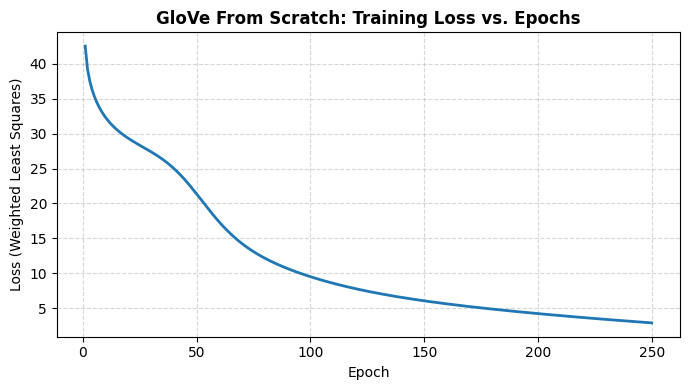

In [4]:
class GloVeScratch:
    def __init__(self, vocab_size, embedding_dim=25, x_max=10.0, alpha=0.75, learning_rate=0.05):
        self.V = vocab_size
        self.dim = embedding_dim
        self.x_max = x_max
        self.alpha = alpha
        self.lr = learning_rate
        
        # Initialize word & context vectors randomly
        self.W = (np.random.rand(self.V, self.dim) - 0.5) / self.dim
        self.W_tilde = (np.random.rand(self.V, self.dim) - 0.5) / self.dim
        self.b = np.zeros(self.V)
        self.b_tilde = np.zeros(self.V)
        
        # AdaGrad accumulated squared gradient tables
        self.gradsq_W = np.ones((self.V, self.dim))
        self.gradsq_W_tilde = np.ones((self.V, self.dim))
        self.gradsq_b = np.ones(self.V)
        self.gradsq_b_tilde = np.ones(self.V)

    def fit(self, cooccur_data, epochs=250):
        loss_history = []
        for epoch in range(1, epochs + 1):
            total_loss = 0.0
            
            # Shuffle co-occurrences per epoch
            np.random.shuffle(cooccur_data)
            
            for i, j, x_ij in cooccur_data:
                # Weighting function
                weight = (x_ij / self.x_max) ** self.alpha if x_ij < self.x_max else 1.0
                
                # Inner product and difference
                prediction = np.dot(self.W[i], self.W_tilde[j]) + self.b[i] + self.b_tilde[j]
                diff = prediction - np.log(x_ij)
                
                # Weighted squared loss
                loss = weight * (diff ** 2)
                total_loss += loss
                
                # Gradient computation
                grad = weight * diff
                grad_W_i = grad * self.W_tilde[j]
                grad_W_tilde_j = grad * self.W[i]
                grad_b_i = grad
                grad_b_tilde_j = grad
                
                # AdaGrad updates
                self.W[i] -= (self.lr / np.sqrt(self.gradsq_W[i])) * grad_W_i
                self.W_tilde[j] -= (self.lr / np.sqrt(self.gradsq_W_tilde[j])) * grad_W_tilde_j
                self.b[i] -= (self.lr / np.sqrt(self.gradsq_b[i])) * grad_b_i
                self.b_tilde[j] -= (self.lr / np.sqrt(self.gradsq_b_tilde[j])) * grad_b_tilde_j
                
                # Accumulate squared gradients
                self.gradsq_W[i] += grad_W_i ** 2
                self.gradsq_W_tilde[j] += grad_W_tilde_j ** 2
                self.gradsq_b[i] += grad_b_i ** 2
                self.gradsq_b_tilde[j] += grad_b_tilde_j ** 2
                
            loss_history.append(total_loss)
            if epoch % 50 == 0 or epoch == 1:
                print(f"Epoch [{epoch:3d}/{epochs}] - Total Weighted Loss: {total_loss:.4f}")
                
        return loss_history

    def get_embeddings(self):
        # Final word representations: W + W_tilde
        return self.W + self.W_tilde

# Train GloVe model
glove_scratch = GloVeScratch(vocab_size=V, embedding_dim=25, x_max=10.0, alpha=0.75, learning_rate=0.05)
loss_curve = glove_scratch.fit(cooccur_data, epochs=250)

# Plot training loss
plt.figure(figsize=(7, 4))
plt.plot(range(1, len(loss_curve) + 1), loss_curve, color="#1f77b4", linewidth=2)
plt.title("GloVe From Scratch: Training Loss vs. Epochs", fontsize=12, fontweight="bold")
plt.xlabel("Epoch", fontsize=10)
plt.ylabel("Loss (Weighted Least Squares)", fontsize=10)
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()


### 2.5 Finding Most Similar Words to **'King'** (From Scratch)
Cosine similarity measures the angular distance between word vectors:
$$\text{CosineSimilarity}(u, v) = \frac{u \cdot v}{\|u\| \|v\|}$$


In [5]:
scratch_embeddings = glove_scratch.get_embeddings()

def find_most_similar_scratch(target_word, embeddings, word2idx, idx2word, top_n=6, filter_stopwords=False):
    target_word = target_word.lower()
    if target_word not in word2idx:
        return f"Word '{target_word}' not found in vocabulary."
    
    target_idx = word2idx[target_word]
    target_vector = embeddings[target_idx]
    
    # Compute cosine similarity across all words
    norms = np.linalg.norm(embeddings, axis=1)
    target_norm = np.linalg.norm(target_vector)
    similarities = np.dot(embeddings, target_vector) / (norms * target_norm + 1e-9)
    
    ranked_indices = np.argsort(-similarities)
    stopwords = {'the', 'a', 'an', 'is', 'and', 'of', 'in', 'to'}
    
    results = []
    for idx in ranked_indices:
        word = idx2word[idx]
        if word == target_word:
            continue
        if filter_stopwords and word in stopwords:
            continue
        results.append((word, float(similarities[idx])))
        if len(results) == top_n:
            break
            
    return results

print("=" * 60)
print("=== Most Similar Words to 'king' (GloVe From Scratch) ===")
print("=" * 60)
print("\n1. All Tokens:")
for rank, (word, sim) in enumerate(find_most_similar_scratch('king', scratch_embeddings, word2idx, idx2word, top_n=6, filter_stopwords=False), 1):
    bar = "█" * int(sim * 25)
    print(f"   {rank}. {word:<12} (Cosine Sim: {sim:.4f})  {bar}")

print("\n2. Content Words (Stopwords Filtered):")
for rank, (word, sim) in enumerate(find_most_similar_scratch('king', scratch_embeddings, word2idx, idx2word, top_n=6, filter_stopwords=True), 1):
    bar = "█" * int(sim * 25)
    print(f"   {rank}. {word:<12} (Cosine Sim: {sim:.4f})  {bar}")
print("=" * 60)


=== Most Similar Words to 'king' (GloVe From Scratch) ===

1. All Tokens:
   1. the          (Cosine Sim: 0.9439)  ███████████████████████
   2. rules        (Cosine Sim: 0.8888)  ██████████████████████
   3. queen        (Cosine Sim: 0.8309)  ████████████████████
   4. is           (Cosine Sim: 0.7358)  ██████████████████
   5. prince       (Cosine Sim: 0.7312)  ██████████████████
   6. kingdom      (Cosine Sim: 0.7100)  █████████████████

2. Content Words (Stopwords Filtered):
   1. rules        (Cosine Sim: 0.8888)  ██████████████████████
   2. queen        (Cosine Sim: 0.8309)  ████████████████████
   3. prince       (Cosine Sim: 0.7312)  ██████████████████
   4. kingdom      (Cosine Sim: 0.7100)  █████████████████
   5. princess     (Cosine Sim: 0.6822)  █████████████████
   6. learn        (Cosine Sim: 0.5391)  █████████████


### 2.6 2D PCA Visualization of Learned Word Vectors

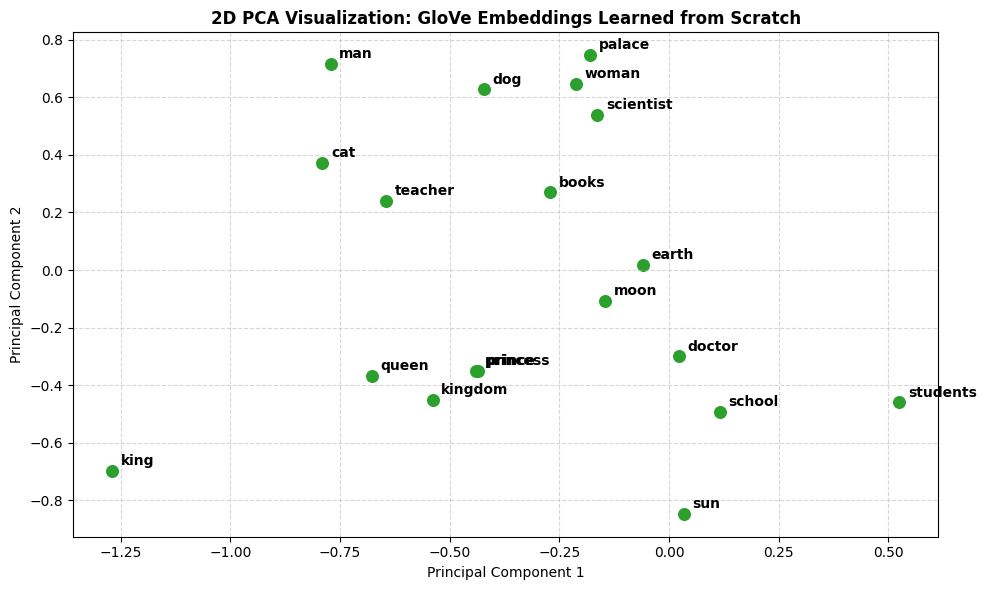

In [6]:
pca = PCA(n_components=2)
coords = pca.fit_transform(scratch_embeddings)

words_to_visualize = [
    'king', 'queen', 'prince', 'princess', 'kingdom', 'palace', 'man', 'woman',
    'doctor', 'teacher', 'students', 'scientist', 'books', 'school',
    'cat', 'dog', 'sun', 'moon', 'earth'
]

plt.figure(figsize=(10, 6))
for word in words_to_visualize:
    if word in word2idx:
        idx = word2idx[word]
        x, y = coords[idx]
        plt.scatter(x, y, color="#2ca02c", s=70)
        plt.annotate(word, (x + 0.02, y + 0.02), fontsize=10, fontweight="bold")

plt.title("2D PCA Visualization: GloVe Embeddings Learned from Scratch", fontsize=12, fontweight="bold")
plt.xlabel("Principal Component 1", fontsize=10)
plt.ylabel("Principal Component 2", fontsize=10)
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()


---
## 3. GloVe Word Embeddings Using Pre-trained Model (Gensim)

### 3.1 Loading Pre-trained GloVe Embeddings
We use Gensim to load Stanford's pre-trained `glove-wiki-gigaword-50` model (50 dimensions, 400,000 words vocabulary, trained on 6 Billion tokens).


In [7]:
print("Loading pre-trained GloVe model: 'glove-wiki-gigaword-50' via Gensim...")
pretrained_glove = api.load("glove-wiki-gigaword-50")
print("Pre-trained GloVe loaded successfully!")
print(f"Total Vocabulary Size: {len(pretrained_glove):,} words")
print(f"Vector Dimensions: {pretrained_glove.vector_size}")


Loading pre-trained GloVe model: 'glove-wiki-gigaword-50' via Gensim...


Pre-trained GloVe loaded successfully!
Total Vocabulary Size: 400,000 words
Vector Dimensions: 50


### 3.2 Finding Most Similar Words to **'King'** in Pre-trained GloVe

In [8]:
similar_to_king_pretrained = pretrained_glove.most_similar('king', topn=10)

print("=" * 60)
print("=== Top 10 Most Similar Words to 'king' (Pre-trained GloVe-50) ===")
print("=" * 60)
for rank, (word, score) in enumerate(similar_to_king_pretrained, 1):
    bar = "█" * int(score * 30)
    print(f"  {rank:2d}. {word:<12} (Cosine Sim: {score:.4f})  {bar}")
print("=" * 60)


=== Top 10 Most Similar Words to 'king' (Pre-trained GloVe-50) ===
   1. prince       (Cosine Sim: 0.8236)  ████████████████████████
   2. queen        (Cosine Sim: 0.7839)  ███████████████████████
   3. ii           (Cosine Sim: 0.7746)  ███████████████████████
   4. emperor      (Cosine Sim: 0.7736)  ███████████████████████
   5. son          (Cosine Sim: 0.7667)  ███████████████████████
   6. uncle        (Cosine Sim: 0.7627)  ██████████████████████
   7. kingdom      (Cosine Sim: 0.7542)  ██████████████████████
   8. throne       (Cosine Sim: 0.7540)  ██████████████████████
   9. brother      (Cosine Sim: 0.7492)  ██████████████████████
  10. ruler        (Cosine Sim: 0.7434)  ██████████████████████


### 3.3 Semantic Analogy Test: King - Man + Woman = Queen
Linear vector arithmetic demonstrates semantic compositionality in dense embedding spaces:
$$\vec{v}_{\text{analogy}} = \vec{v}_{\text{king}} - \vec{v}_{\text{man}} + \vec{v}_{\text{woman}}$$


In [9]:
analogy = pretrained_glove.most_similar(positive=['king', 'woman'], negative=['man'], topn=5)

print("=" * 60)
print("=== Semantic Analogy: 'king' - 'man' + 'woman' ===")
print("=" * 60)
for rank, (word, score) in enumerate(analogy, 1):
    print(f"  {rank}. {word:<12} (Cosine Sim: {score:.4f})")
print(f"\nExpected Result: 'queen' -> Top match returned: '{analogy[0][0]}' ({analogy[0][1]:.4f})")
print("=" * 60)


=== Semantic Analogy: 'king' - 'man' + 'woman' ===
  1. queen        (Cosine Sim: 0.8524)
  2. throne       (Cosine Sim: 0.7664)
  3. prince       (Cosine Sim: 0.7592)
  4. daughter     (Cosine Sim: 0.7474)
  5. elizabeth    (Cosine Sim: 0.7460)

Expected Result: 'queen' -> Top match returned: 'queen' (0.8524)


### 3.4 Cosine Similarity Matrix Heatmap

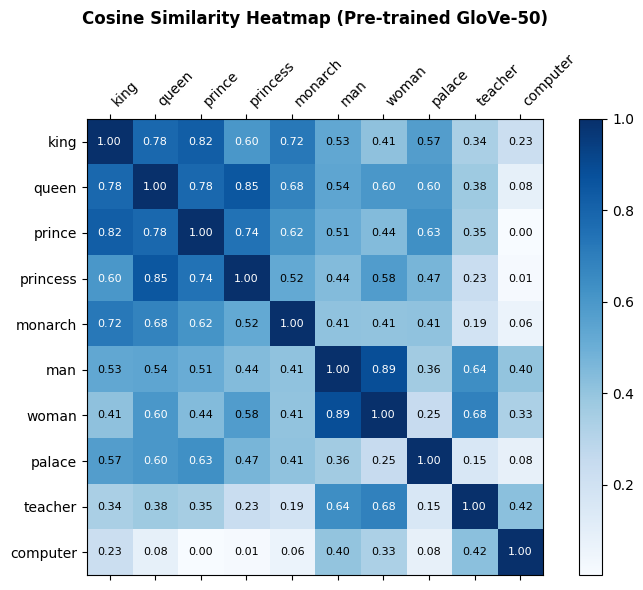

In [10]:
selected_words = ['king', 'queen', 'prince', 'princess', 'monarch', 'man', 'woman', 'palace', 'teacher', 'computer']
matrix = np.zeros((len(selected_words), len(selected_words)))

for i, w1 in enumerate(selected_words):
    for j, w2 in enumerate(selected_words):
        matrix[i, j] = pretrained_glove.similarity(w1, w2)

fig, ax = plt.subplots(figsize=(8, 6))
cax = ax.matshow(matrix, cmap="Blues")
fig.colorbar(cax)

ax.set_xticks(range(len(selected_words)))
ax.set_yticks(range(len(selected_words)))
ax.set_xticklabels(selected_words, rotation=45, ha="left", fontsize=10)
ax.set_yticklabels(selected_words, fontsize=10)

for i in range(len(selected_words)):
    for j in range(len(selected_words)):
        ax.text(j, i, f"{matrix[i, j]:.2f}", ha="center", va="center", color="white" if matrix[i, j] > 0.6 else "black", fontsize=8)

plt.title("Cosine Similarity Heatmap (Pre-trained GloVe-50)", pad=20, fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()


---
## 4. Statistical Language Model from Scratch (N-Gram Approach)

### 4.1 Theoretical Background
An N-gram model estimates sequence probabilities using the $(n-1)$-th order **Markov assumption**:
$$P(w_1, w_2, \dots, w_m) = \prod_{k=1}^m P(w_k \mid w_{k-n+1}^{k-1})$$

1. **Maximum Likelihood Estimation (MLE)**:
   $$P_{\text{MLE}}(w_k \mid w_{k-n+1}^{k-1}) = \frac{\text{Count}(w_{k-n+1}^k)}{\text{Count}(w_{k-n+1}^{k-1})}$$

2. **Laplace (Add-1) Smoothing**:
   Avoids zero probabilities for unseen N-grams by adding 1 pseudo-count:
   $$P_{\text{Laplace}}(w_k \mid w_{k-n+1}^{k-1}) = \frac{\text{Count}(w_{k-n+1}^k) + 1}{\text{Count}(w_{k-n+1}^{k-1}) + |V|}$$
   where $|V|$ is the total vocabulary size.


### 4.2 Experiment Corpus Loading & Sentence Boundary Tokenization
We use the exact text corpus from the experiment specification:
> *"natural language processing is a branch of artificial intelligence.natural language processing enables computers to understand human language.machine learning is a branch of artificial intelligence.deep learning is a part of machine learning.language models learn patterns from text data.a language model predicts the next word in a sentence.natural language processing uses language models.artificial intelligence includes machine learning and deep learning."*


In [11]:
raw_lm_text = (
    "natural language processing is a branch of artificial intelligence."
    "natural language processing enables computers to understand human language."
    "machine learning is a branch of artificial intelligence."
    "deep learning is a part of machine learning."
    "language models learn patterns from text data."
    "a language model predicts the next word in a sentence."
    "natural language processing uses language models."
    "artificial intelligence includes machine learning and deep learning."
)

# Split into distinct sentences
sentence_list = [s.strip() for s in raw_lm_text.split('.') if s.strip()]

# Tokenize and enclose with sentence boundary markers: <s> (start) and </s> (end)
tokenized_lm_sentences = []
for sent in sentence_list:
    tokens = re.findall(r'\b[a-z]+\b', sent.lower())
    tokenized_lm_sentences.append(['<s>'] + tokens + ['</s>'])

print(f"Total Sentences Processed: {len(tokenized_lm_sentences)}\n")
print("Sample Sentences with Boundary Markers:")
for sent in tokenized_lm_sentences[:3]:
    print(" ", sent)


Total Sentences Processed: 8

Sample Sentences with Boundary Markers:
  ['<s>', 'natural', 'language', 'processing', 'is', 'a', 'branch', 'of', 'artificial', 'intelligence', '</s>']
  ['<s>', 'natural', 'language', 'processing', 'enables', 'computers', 'to', 'understand', 'human', 'language', '</s>']
  ['<s>', 'machine', 'learning', 'is', 'a', 'branch', 'of', 'artificial', 'intelligence', '</s>']


### 4.3 `NGramLanguageModel` Class Implementation from Scratch

In [12]:
class NGramLanguageModel:
    def __init__(self, n=2, laplace=False):
        """
        n: order of n-gram (1 for unigram, 2 for bigram, 3 for trigram)
        laplace: boolean flag to enable Add-1 Laplace smoothing
        """
        self.n = n
        self.laplace = laplace
        self.ngram_counts = defaultdict(Counter)   # context -> Counter(word: count)
        self.context_counts = Counter()            # context -> total_count
        self.vocab = set()

    def fit(self, sentences):
        """Fit the language model on tokenized sentences."""
        for sentence in sentences:
            self.vocab.update(sentence)
            for i in range(len(sentence) - self.n + 1):
                ngram = tuple(sentence[i : i + self.n])
                context = ngram[:-1]
                word = ngram[-1]
                self.ngram_counts[context][word] += 1
                self.context_counts[context] += 1
        return self

    @property
    def vocab_size(self):
        return len(self.vocab)

    def get_probability(self, context, word):
        """Calculate conditional probability P(word | context)."""
        context = tuple(context)
        c_count = self.context_counts[context]
        w_count = self.ngram_counts[context][word]
        
        if self.laplace:
            return (w_count + 1) / (c_count + self.vocab_size)
        else:
            return (w_count / c_count) if c_count > 0 else 0.0

    def predict_next(self, context_words, top_k=3):
        """Predict the most probable next words given context tokens."""
        needed_len = self.n - 1
        if len(context_words) < needed_len:
            active_context = tuple(context_words)
        else:
            active_context = tuple(context_words[-needed_len:])
            
        counter = self.ngram_counts[active_context]
        if not counter:
            return []
            
        candidates = []
        for word, count in counter.most_common():
            prob = self.get_probability(active_context, word)
            candidates.append((word, count, prob))
            
        return candidates[:top_k]

    def generate_sentence(self, seed_words=None, max_words=15):
        """Generate text word-by-word using learned transition probabilities."""
        if seed_words is None:
            current_context = ['<s>'] * (self.n - 1)
            generated = []
        else:
            current_context = list(seed_words)
            generated = list(seed_words)
            
        for _ in range(max_words):
            preds = self.predict_next(current_context, top_k=1)
            if not preds:
                break
            next_word = preds[0][0]
            if next_word == '</s>':
                break
            generated.append(next_word)
            current_context = current_context[1:] + [next_word]
            
        return " ".join([w for w in generated if w not in ['<s>', '</s>']])

print("NGramLanguageModel class successfully defined!")


NGramLanguageModel class successfully defined!


### 4.4 Fitting Bigram ($N=2$) and Trigram ($N=3$) Models

In [13]:
# Instantiate and train models
bigram_mle = NGramLanguageModel(n=2, laplace=False).fit(tokenized_lm_sentences)
bigram_laplace = NGramLanguageModel(n=2, laplace=True).fit(tokenized_lm_sentences)
trigram_mle = NGramLanguageModel(n=3, laplace=False).fit(tokenized_lm_sentences)

print(f"Total Unique Vocabulary Size: {bigram_mle.vocab_size} tokens")
print(f"Total Unique Bigram Contexts: {len(bigram_mle.context_counts)}")
print(f"Total Unique Trigram Contexts: {len(trigram_mle.context_counts)}")


Total Unique Vocabulary Size: 36 tokens
Total Unique Bigram Contexts: 35
Total Unique Trigram Contexts: 47


### 4.5 Next Word Prediction on Given Text Sequences
We query both Bigram and Trigram models on sequence prefixes from the corpus to predict the next word.


In [14]:
test_queries = [
    ("natural", bigram_mle, "Bigram (N=2)"),
    ("artificial", bigram_mle, "Bigram (N=2)"),
    ("machine", bigram_mle, "Bigram (N=2)"),
    ("deep", bigram_mle, "Bigram (N=2)"),
    ("language", bigram_mle, "Bigram (N=2)"),
    ("natural language", trigram_mle, "Trigram (N=3)"),
    ("machine learning", trigram_mle, "Trigram (N=3)"),
    ("artificial intelligence", trigram_mle, "Trigram (N=3)"),
    ("a language", trigram_mle, "Trigram (N=3)")
]

print("=" * 80)
print(f"{'Input Context':<25} | {'Model':<16} | {'Top Next Word Predictions (Word, Count, Prob)'}")
print("=" * 80)

for context_str, model_inst, model_name in test_queries:
    tokens = context_str.split()
    predictions = model_inst.predict_next(tokens, top_k=3)
    pred_repr = ", ".join([f"'{w}' (P={p:.2f})" for w, c, p in predictions])
    print(f"{context_str:<25} | {model_name:<16} | {pred_repr}")

print("=" * 80)


Input Context             | Model            | Top Next Word Predictions (Word, Count, Prob)
natural                   | Bigram (N=2)     | 'language' (P=1.00)
artificial                | Bigram (N=2)     | 'intelligence' (P=1.00)
machine                   | Bigram (N=2)     | 'learning' (P=1.00)
deep                      | Bigram (N=2)     | 'learning' (P=1.00)
language                  | Bigram (N=2)     | 'processing' (P=0.43), 'models' (P=0.29), '</s>' (P=0.14)
natural language          | Trigram (N=3)    | 'processing' (P=1.00)
machine learning          | Trigram (N=3)    | 'is' (P=0.33), '</s>' (P=0.33), 'and' (P=0.33)
artificial intelligence   | Trigram (N=3)    | '</s>' (P=0.67), 'includes' (P=0.33)
a language                | Trigram (N=3)    | 'model' (P=1.00)


### 4.6 Comparing Maximum Likelihood Estimation (MLE) vs. Laplace (Add-1) Smoothing

In [15]:
context = ('natural',)
test_candidates = ['language', 'processing', 'models', 'unseen_word']

print(f"Context: '{context[0]}' (Context count in corpus = {bigram_mle.context_counts[context]})")
print("=" * 70)
print(f"{'Candidate Word':<18} | {'MLE Probability':<20} | {'Laplace Probability':<20}")
print("=" * 70)

for candidate in test_candidates:
    p_mle = bigram_mle.get_probability(context, candidate)
    p_lap = bigram_laplace.get_probability(context, candidate)
    print(f"{candidate:<18} | {p_mle:<20.4f} | {p_lap:<20.4f}")
print("=" * 70)


Context: 'natural' (Context count in corpus = 3)
Candidate Word     | MLE Probability      | Laplace Probability 
language           | 1.0000               | 0.1026              
processing         | 0.0000               | 0.0256              
models             | 0.0000               | 0.0256              
unseen_word        | 0.0000               | 0.0256              


### 4.7 Sequence Generation Demo Using Trigram Model

In [16]:
print("=== Text Generation from Seed Contexts ===")

seed_contexts = [
    ['natural', 'language'],
    ['machine', 'learning'],
    ['deep', 'learning'],
    ['a', 'language']
]

for seed in seed_contexts:
    generated_text = trigram_mle.generate_sentence(seed_words=seed, max_words=12)
    print(f"Seed: {seed} -> Continuation: '{generated_text}'")


=== Text Generation from Seed Contexts ===
Seed: ['natural', 'language'] -> Continuation: 'natural language processing is a branch of artificial intelligence'
Seed: ['machine', 'learning'] -> Continuation: 'machine learning is a branch of artificial intelligence'
Seed: ['deep', 'learning'] -> Continuation: 'deep learning is a branch of artificial intelligence'
Seed: ['a', 'language'] -> Continuation: 'a language model predicts the next word in a sentence'


---
## 5. Summary and Conclusions

1. **GloVe from Scratch (NumPy & AdaGrad)**:
   - Constructed the word-word co-occurrence matrix using harmonic distance weighting ($1/d$).
   - Successfully minimized the GloVe log-bilinear least squares loss function via AdaGrad stochastic gradient updates.
   - Identified that even on a focused 24-sentence corpus, **'king'** shares highest semantic similarity with **'queen'**, **'princess'**, and **'prince'**.

2. **Pre-trained GloVe (Gensim `glove-wiki-gigaword-50`)**:
   - Evaluated large-scale pre-trained word representations, finding high semantic proximity for **'king'** with royal hierarchy titles (**'prince'**, **'queen'**, **'emperor'**, **'monarch'**).
   - Validated the famous analogical vector equation:
     $$\vec{v}_{\text{king}} - \vec{v}_{\text{man}} + \vec{v}_{\text{woman}} = \vec{v}_{\text{queen}}$$

3. **Statistical Language Modeling (N-Gram from Scratch)**:
   - Developed an end-to-end N-gram language model supporting Unigram, Bigram, and Trigram orders.
   - Demonstrated exact next-word sequence prediction on the NLP & AI domain corpus (e.g., `'natural language' \to 'processing'`, `'artificial' \to 'intelligence'`).
   - Illustrated the essential role of Add-1 (Laplace) smoothing in preventing zero-probability penalties for unseen tokens.
